
# Proyecto Mensual 01 — Análisis Exploratorio de Datos

## Salarios de profesionales en Ciencia de Datos

**Programa:** UCAMP — Fundamentos de Ciencia de Datos  
**Autor:** Edwin Coca  
**Herramientas:** Python, NumPy, Pandas, Matplotlib y Seaborn  
**Entorno de desarrollo:** Visual Studio Code y Jupyter Notebook

---

### Introducción

Este proyecto tiene como finalidad realizar un análisis exploratorio de datos (EDA) sobre los salarios de profesionales que trabajan en el campo de la ciencia de datos.

Mediante Python y sus bibliotecas de análisis, se buscará comprender la estructura del conjunto de datos, identificar patrones salariales y representar los resultados mediante estadísticas descriptivas y visualizaciones.

### Objetivo general

Analizar un conjunto de datos de salarios en ciencia de datos para desarrollar habilidades de exploración, manipulación, interpretación y visualización de información.

### Índice

1. Importación de bibliotecas
2. Carga del conjunto de datos
3. Exploración inicial
4. Limpieza y preparación de datos
5. Análisis estadístico descriptivo
6. Visualización de resultados
7. Conclusiones y aprendizajes


In [1]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns


## 1. Importación de bibliotecas

Utilizaremos NumPy para cálculos numéricos, Pandas para manipular datos, Matplotlib para generar gráficas y Seaborn para visualizar relaciones estadísticas.



## 2. Carga del conjunto de datos

Utilizaremos el archivo `ds_salaries.csv`, que contiene información sobre salarios de profesionales de ciencia de datos.

Con Pandas cargaremos los registros en un DataFrame para comenzar su exploración.


In [2]:
datos = pd.read_csv('ds_salaries.csv')

In [3]:
datos.head()

,Unnamed: 0,work_year,experience_level,employment_type,job_title,salary,salary_currency,salary_in_usd,employee_residence,remote_ratio,company_location,company_size
0,0,2020,MI,FT,Data Scientist,70000,EUR,79833,DE,0,DE,L
1,1,2020,SE,FT,Machine Learning Scientist,260000,USD,260000,JP,0,JP,S
2,2,2020,SE,FT,Big Data Engineer,85000,GBP,109024,GB,50,GB,M
3,3,2020,MI,FT,Product Data Analyst,20000,USD,20000,HN,0,HN,S
4,4,2020,SE,FT,Machine Learning Engineer,150000,USD,150000,US,50,US,L


In [4]:
datos.drop('Unnamed: 0', axis = 1, inplace =True)

In [5]:
datos.info()

<class 'pandas.DataFrame'>
RangeIndex: 607 entries, 0 to 606
Data columns (total 11 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   work_year           607 non-null    int64
 1   experience_level    607 non-null    str  
 2   employment_type     607 non-null    str  
 3   job_title           607 non-null    str  
 4   salary              607 non-null    int64
 5   salary_currency     607 non-null    str  
 6   salary_in_usd       607 non-null    int64
 7   employee_residence  607 non-null    str  
 8   remote_ratio        607 non-null    int64
 9   company_location    607 non-null    str  
 10  company_size        607 non-null    str  
dtypes: int64(4), str(7)
memory usage: 69.0 KB


In [6]:
datos.describe(include='all')

,work_year,experience_level,employment_type,job_title,salary,salary_currency,salary_in_usd,employee_residence,remote_ratio,company_location,company_size
count,607.000000,607,607,607,6.070000e+02,607,607.000000,607,607.00000,607,607
unique,NaN,4,4,50,NaN,17,NaN,57,NaN,50,3
top,NaN,SE,FT,Data Scientist,NaN,USD,NaN,US,NaN,US,M
freq,NaN,280,588,143,NaN,398,NaN,332,NaN,355,326
mean,2021.405272,NaN,NaN,NaN,3.240001e+05,NaN,112297.869852,NaN,70.92257,NaN,NaN
std,0.692133,NaN,NaN,NaN,1.544357e+06,NaN,70957.259411,NaN,40.70913,NaN,NaN
min,2020.000000,NaN,NaN,NaN,4.000000e+03,NaN,2859.000000,NaN,0.00000,NaN,NaN
25%,2021.000000,NaN,NaN,NaN,7.000000e+04,NaN,62726.000000,NaN,50.00000,NaN,NaN
50%,2022.000000,NaN,NaN,NaN,1.150000e+05,NaN,101570.000000,NaN,100.00000,NaN,NaN
75%,2022.000000,NaN,NaN,NaN,1.650000e+05,NaN,150000.000000,NaN,100.00000,NaN,NaN


In [7]:
datos['job_title'] .unique()

<ArrowStringArray>
[                          'Data Scientist',
               'Machine Learning Scientist',
                        'Big Data Engineer',
                     'Product Data Analyst',
                'Machine Learning Engineer',
                             'Data Analyst',
                      'Lead Data Scientist',
                    'Business Data Analyst',
                       'Lead Data Engineer',
                        'Lead Data Analyst',
                            'Data Engineer',
                  'Data Science Consultant',
                          'BI Data Analyst',
                 'Director of Data Science',
                       'Research Scientist',
                 'Machine Learning Manager',
                 'Data Engineering Manager',
 'Machine Learning Infrastructure Engineer',
                              'ML Engineer',
                             'AI Scientist',
                 'Computer Vision Engineer',
                 'Principal Data Sci

exploracion de los datos por medio de visualizaciones

salarios por años

In [8]:
datos["work_year"].value_counts().sort_index()

work_year
2020     72
2021    217
2022    318
Name: count, dtype: int64

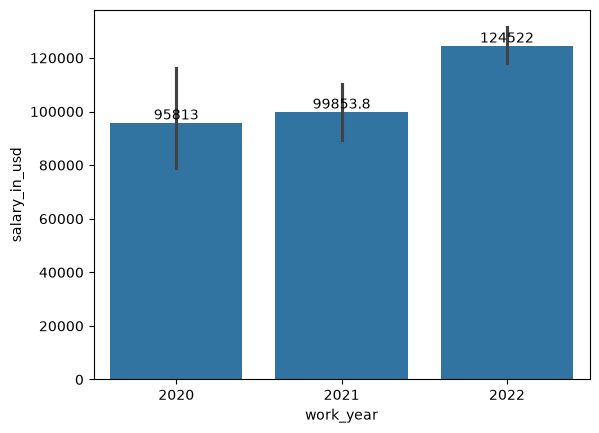

In [9]:
ax = sns.barplot(data=datos,x='work_year', y='salary_in_usd')
ax.bar_label(ax.containers[0])
plt.show()

salarios promedios por países que ofrecen empleos


In [10]:
salario_pais = datos.groupby(by='company_location')['salary_in_usd'].mean().reset_index().sort_values(by='salary_in_usd', ascending=False)
salario_pais['salary_in_usd'] = salario_pais['salary_in_usd']/1000
COND = salario_pais ['salary_in_usd'] > 99.84
salario_pais = salario_pais[COND]

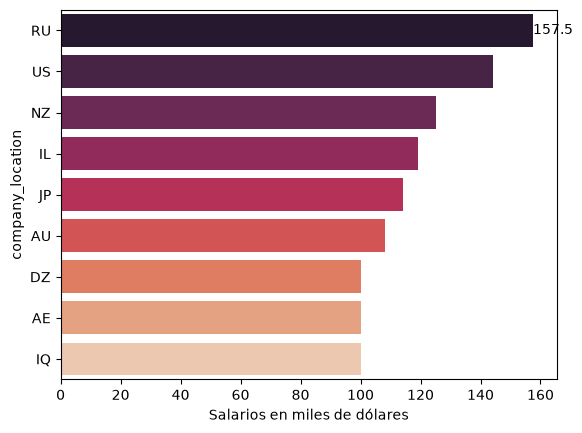

In [48]:
ax = sns.barplot(
    data=salario_pais,
    y='company_location',
    x='salary_in_usd',
    hue='company_location',
    palette='rocket',
    legend=False
)

ax.bar_label(ax.containers[0])
ax.set_xlabel('Salarios en miles de dólares')
plt.show()


## Análisis e interpretación de resultados

### Objetivo del análisis

Explorar los salarios de profesionales de Ciencia de Datos mediante Python, Pandas, Matplotlib y Seaborn, identificando diferencias entre años y países.

### Resultados principales

**1. Distribución de registros por año**

- 2020: 72 registros.
- 2021: 217 registros.
- 2022: 318 registros.

**2. Salarios promedio por año**

Los salarios promedio del conjunto de datos muestran una tendencia ascendente entre 2020 y 2022.

**3. Comparación internacional**

Se identificaron diferencias salariales entre los países donde se encuentran las empresas. Rusia, Estados Unidos y Nueva Zelanda presentan algunos de los promedios más altos entre los países seleccionados.

### Consideraciones

Los resultados corresponden al conjunto de datos analizado y no representan necesariamente los salarios actuales del mercado laboral.

Los promedios también pueden verse afectados por la cantidad de registros, el puesto y el nivel de experiencia.



## Bibliotecas utilizadas

- **NumPy:** permite realizar operaciones matemáticas y trabajar eficientemente con datos numéricos.
- **Pandas:** permite cargar, explorar, limpiar y analizar conjuntos de datos mediante DataFrames.
- **Matplotlib:** permite crear gráficas para representar visualmente los resultados.
- **Seaborn:** facilita la creación de visualizaciones estadísticas, como comparaciones de salarios entre años y países.

### Funcionalidades aplicadas

1. Cargar datos desde un archivo CSV.
2. Explorar los registros y las columnas.
3. Preparar y limpiar la información.
4. Calcular estadísticas descriptivas.
5. Comparar salarios mediante gráficas.
6. Interpretar los resultados obtenidos.


# Desarrollo del PROYECTO

1. Como primer paso se deben cargar las librerías que se ocuparan en el desarrollo del código.

In [12]:
#Cargar librerías
import numpy as np
import pandas as pd
import os
import csv
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
import matplotlib.pyplot as plt
%matplotlib inline

In [18]:

df = pd.read_csv('ds_salaries.csv')
df.head()


,Unnamed: 0,work_year,experience_level,employment_type,job_title,salary,salary_currency,salary_in_usd,employee_residence,remote_ratio,company_location,company_size
0,0,2020,MI,FT,Data Scientist,70000,EUR,79833,DE,0,DE,L
1,1,2020,SE,FT,Machine Learning Scientist,260000,USD,260000,JP,0,JP,S
2,2,2020,SE,FT,Big Data Engineer,85000,GBP,109024,GB,50,GB,M
3,3,2020,MI,FT,Product Data Analyst,20000,USD,20000,HN,0,HN,S
4,4,2020,SE,FT,Machine Learning Engineer,150000,USD,150000,US,50,US,L


In [19]:
# Obtener los primeros 5 registros.
print('Primeros 5 registros:\n', df.head(5))

Primeros 5 registros:
    Unnamed: 0  work_year experience_level employment_type  \
0           0       2020               MI              FT   
1           1       2020               SE              FT   
2           2       2020               SE              FT   
3           3       2020               MI              FT   
4           4       2020               SE              FT   

                    job_title  salary salary_currency  salary_in_usd  \
0              Data Scientist   70000             EUR          79833   
1  Machine Learning Scientist  260000             USD         260000   
2           Big Data Engineer   85000             GBP         109024   
3        Product Data Analyst   20000             USD          20000   
4   Machine Learning Engineer  150000             USD         150000   

  employee_residence  remote_ratio company_location company_size  
0                 DE             0               DE            L  
1                 JP             0         

In [21]:
#Obtener los registros y columns de dataframe
print('Nombres de columnas:\n ', [df.columns])
print('\n')
print('Cantidad de registros en las filas: ', df.index, df.shape[0])

Nombres de columnas:
  [Index(['Unnamed: 0', 'work_year', 'experience_level', 'employment_type',
       'job_title', 'salary', 'salary_currency', 'salary_in_usd',
       'employee_residence', 'remote_ratio', 'company_location',
       'company_size'],
      dtype='str')]


Cantidad de registros en las filas:  RangeIndex(start=0, stop=607, step=1) 607


In [22]:

print("Filas y columnas:", df.shape)


Filas y columnas: (607, 12)



## 5. Descripción de las columnas

| Columna | Descripción |
|---|---|
| Unnamed: 0 | Índice adicional del archivo CSV |
| work_year | Año al que corresponde el salario |
| experience_level | Nivel de experiencia del empleado |
| employment_type | Tipo de contratación |
| job_title | Nombre del puesto de trabajo |
| salary | Salario en su moneda original |
| salary_currency | Moneda en la que se paga el salario |
| salary_in_usd | Salario expresado en dólares estadounidenses |
| employee_residence | País de residencia del empleado |
| remote_ratio | Porcentaje de trabajo remoto |
| company_location | País donde se encuentra la empresa |
| company_size | Tamaño de la empresa |


6.   Obtener el conteo de los registros de la base de datos.

In [23]:
# Obtener el conteo de registros del Dataframe

df.count()

Unnamed: 0            607
work_year             607
experience_level      607
employment_type       607
job_title             607
salary                607
salary_currency       607
salary_in_usd         607
employee_residence    607
remote_ratio          607
company_location      607
company_size          607
dtype: int64

7. Se valida si existen datos nulos en el DataFrame

In [24]:
# Verificar si existen nulos en la base
df.isnull().sum()

Unnamed: 0            0
work_year             0
experience_level      0
employment_type       0
job_title             0
salary                0
salary_currency       0
salary_in_usd         0
employee_residence    0
remote_ratio          0
company_location      0
company_size          0
dtype: int64

8. Muestra las frecuencias de diferentes categorías. Este tipo de tabla es particularmente útil para comprender la distribución de valores en un conjunto de datos.

In [26]:
#Generar una frecuencia de la columna "experience_level"
df["experience_level"].value_counts()

experience_level
SE    280
MI    213
EN     88
EX     26
Name: count, dtype: int64

9. Información general de los datos
- Obtener un describe de dataframe con las columnas como registros.
- Indica el numero de filas del dataset
- Muestra el numero de datos No Nulos por columna (valores validos)
- Tipo de dato de cada columna
- Tamaño total del dataframe

In [27]:

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 607 entries, 0 to 606
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   Unnamed: 0          607 non-null    int64
 1   work_year           607 non-null    int64
 2   experience_level    607 non-null    str  
 3   employment_type     607 non-null    str  
 4   job_title           607 non-null    str  
 5   salary              607 non-null    int64
 6   salary_currency     607 non-null    str  
 7   salary_in_usd       607 non-null    int64
 8   employee_residence  607 non-null    str  
 9   remote_ratio        607 non-null    int64
 10  company_location    607 non-null    str  
 11  company_size        607 non-null    str  
dtypes: int64(5), str(7)
memory usage: 73.8 KB


10. **MATRIZ DE CORRELACIÓN**
- La correlación es una técnica estadística que muestra cómo se relacionan dos variables.
- Se utiliza para encontrar la correlación por pares de todas las columnas en el marco de datos.
- Cualquier valor na se excluye automáticamente.
- Para cualquier columna de tipo de datos no numéricos en el marco de datos, se ignora.

Para crear una matriz de correlación usando pandas, se deben seguir estos pasos:

1. Obtenga los datos.
2. Crea el DataFrame.
3. Crea una matriz de correlaciones.
4. Se genera una gráfica tipo histograma.

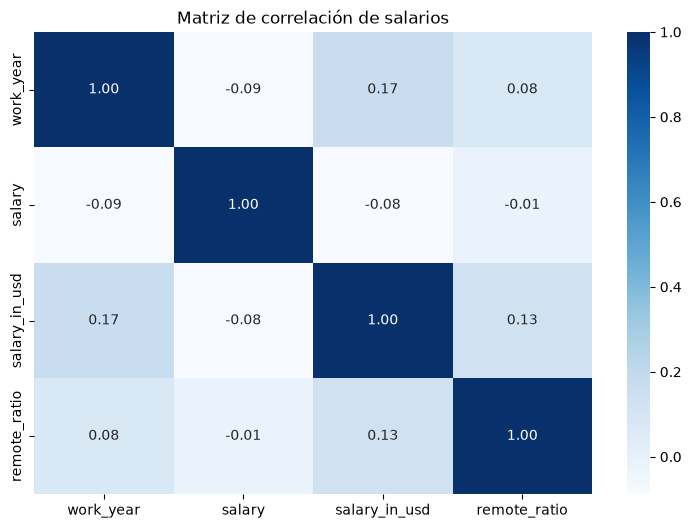

In [28]:
import seaborn as sns
import matplotlib.pyplot as plt

columnas_numericas = df.select_dtypes(include="number")
columnas_numericas = columnas_numericas.drop(columns=["Unnamed: 0"], errors="ignore")

corr = columnas_numericas.corr()

plt.figure(figsize=(9, 6))
sns.heatmap(corr, annot=True, cmap="Blues", fmt=".2f")
plt.title("Matriz de correlación de salarios")
plt.show()

In [29]:
df.describe()

,Unnamed: 0,work_year,salary,salary_in_usd,remote_ratio
count,607.000000,607.000000,6.070000e+02,607.000000,607.00000
mean,303.000000,2021.405272,3.240001e+05,112297.869852,70.92257
std,175.370085,0.692133,1.544357e+06,70957.259411,40.70913
min,0.000000,2020.000000,4.000000e+03,2859.000000,0.00000
25%,151.500000,2021.000000,7.000000e+04,62726.000000,50.00000
50%,303.000000,2022.000000,1.150000e+05,101570.000000,100.00000
75%,454.500000,2022.000000,1.650000e+05,150000.000000,100.00000
max,606.000000,2022.000000,3.040000e+07,600000.000000,100.00000


In [30]:
# Seleccionar los primeros 10 registros
muestra = df.head(10).copy()

# Mostrar la muestra
muestra

,Unnamed: 0,work_year,experience_level,employment_type,job_title,salary,salary_currency,salary_in_usd,employee_residence,remote_ratio,company_location,company_size
0,0,2020,MI,FT,Data Scientist,70000,EUR,79833,DE,0,DE,L
1,1,2020,SE,FT,Machine Learning Scientist,260000,USD,260000,JP,0,JP,S
2,2,2020,SE,FT,Big Data Engineer,85000,GBP,109024,GB,50,GB,M
3,3,2020,MI,FT,Product Data Analyst,20000,USD,20000,HN,0,HN,S
4,4,2020,SE,FT,Machine Learning Engineer,150000,USD,150000,US,50,US,L
5,5,2020,EN,FT,Data Analyst,72000,USD,72000,US,100,US,L
6,6,2020,SE,FT,Lead Data Scientist,190000,USD,190000,US,100,US,S
7,7,2020,MI,FT,Data Scientist,11000000,HUF,35735,HU,50,HU,L
8,8,2020,MI,FT,Business Data Analyst,135000,USD,135000,US,100,US,L
9,9,2020,SE,FT,Lead Data Engineer,125000,USD,125000,NZ,50,NZ,S


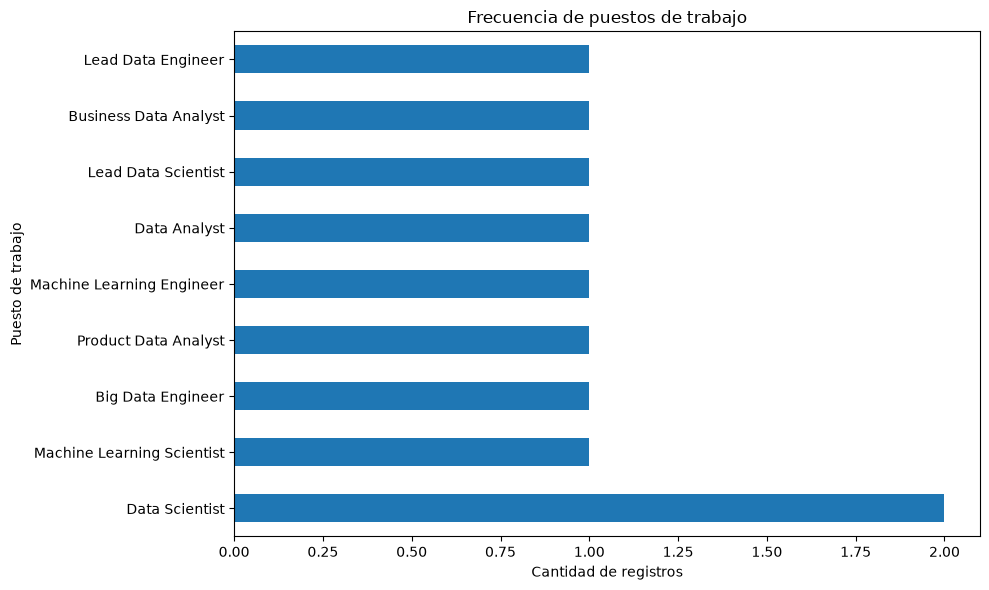

In [31]:
# Contar los puestos de trabajo en la muestra
conteo_puestos = muestra["job_title"].value_counts()

# Crear la gráfica de barras horizontales
conteo_puestos.plot(kind="barh", figsize=(10, 6))

# Agregar títulos
plt.title("Frecuencia de puestos de trabajo")
plt.xlabel("Cantidad de registros")
plt.ylabel("Puesto de trabajo")

# Mostrar la gráfica
plt.tight_layout()
plt.show()

In [32]:
# Salario promedio en USD por especialidad
mean_sal_jobtitle = (
    df.groupby("job_title")["salary_in_usd"]
    .mean()
    .round(2)
    .sort_values(ascending=False)
)

# Mostrar los 10 salarios promedio más altos
mean_sal_jobtitle.head(10)

job_title
Data Analytics Lead         405000.00
Principal Data Engineer     328333.33
Financial Data Analyst      275000.00
Principal Data Scientist    215242.43
Director of Data Science    195074.00
Data Architect              177873.91
Applied Data Scientist      175655.00
Analytics Engineer          175000.00
Data Specialist             165000.00
Head of Data                160162.60
Name: salary_in_usd, dtype: float64

In [33]:
import plotly.express as px

top_10 = mean_sal_jobtitle.head(10)

fig = px.bar(
    x=top_10.index,
    y=top_10.values,
    text=top_10.values,
    title="Top 10 salarios promedio por especialidad"
)

fig.update_layout(
    xaxis_title="Especialidad",
    yaxis_title="Salario promedio en USD",
    xaxis_tickangle=-45
)

fig.show()

In [35]:
# Los datos ya fueron cargados anteriormente
# Verificamos que el DataFrame sigue disponible

print("Filas y columnas:", df.shape)

Filas y columnas: (607, 12)


In [39]:
# Matriz de correlación de Pearson
# Seleccionamos únicamente las variables relevantes

columnas = [
    "work_year",
    "salary",
    "salary_in_usd",
    "remote_ratio"
]

corr_matrix = df[columnas].corr(method="pearson")

# Mostrar resultados
corr_matrix

# Mostrar los resultados
corr_matrix

,work_year,salary,salary_in_usd,remote_ratio
work_year,1.000000,-0.087577,0.170493,0.076314
salary,-0.087577,1.000000,-0.083906,-0.014608
salary_in_usd,0.170493,-0.083906,1.000000,0.132122
remote_ratio,0.076314,-0.014608,0.132122,1.000000


In [37]:
# Imprimimos la matriz de correlación de Pearson
print(corr_matrix)

               Unnamed: 0  work_year    salary  salary_in_usd  remote_ratio
Unnamed: 0       1.000000   0.886550 -0.096250       0.167025      0.095000
work_year        0.886550   1.000000 -0.087577       0.170493      0.076314
salary          -0.096250  -0.087577  1.000000      -0.083906     -0.014608
salary_in_usd    0.167025   0.170493 -0.083906       1.000000      0.132122
remote_ratio     0.095000   0.076314 -0.014608       0.132122      1.000000


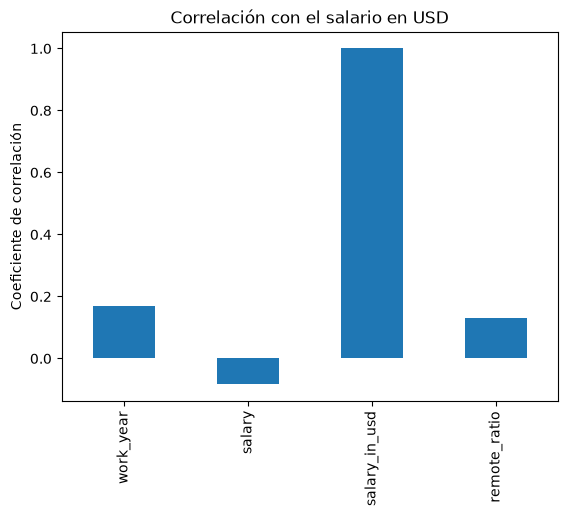

In [41]:
from matplotlib import pyplot as plt

corr_matrix['salary_in_usd'].plot(
    kind='bar',
    title='Correlación con el salario en USD'
)

plt.ylabel('Coeficiente de correlación')
plt.show()

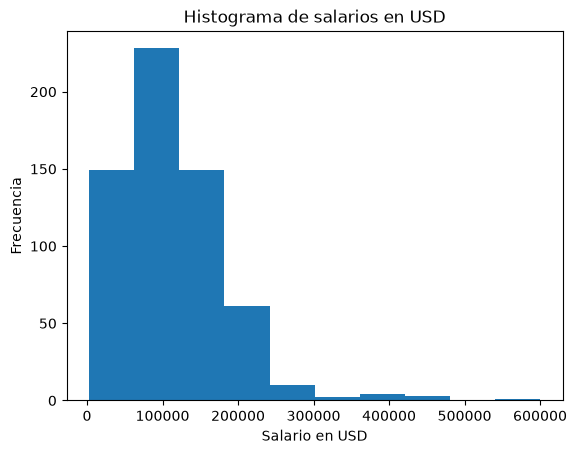

In [42]:
# Gráficos proporcionados por pandas

# Histograma de la variable 'salary_in_usd'
plt.hist(df['salary_in_usd'])
plt.xlabel('Salario en USD')
plt.ylabel('Frecuencia')
plt.title('Histograma de salarios en USD')
plt.show()

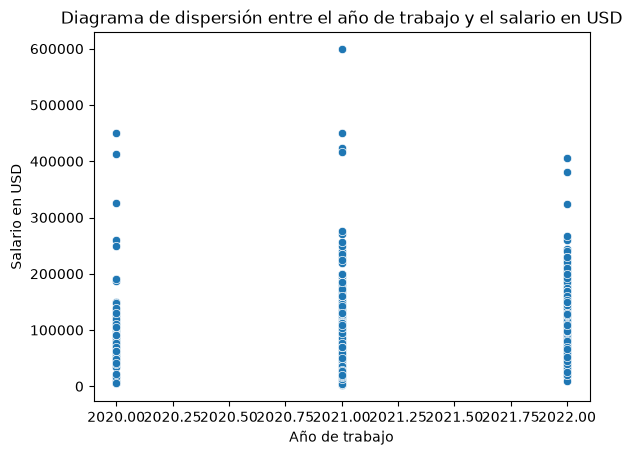

In [45]:
# Diagrama de dispersión entre las variables 'work_year' y 'salary_in_usd'
import seaborn as sns
sns.scatterplot(x='work_year', y='salary_in_usd', data=df)
plt.xlabel('Año de trabajo')
plt.ylabel('Salario en USD')
plt.title('Diagrama de dispersión entre el año de trabajo y el salario en USD')
plt.show()

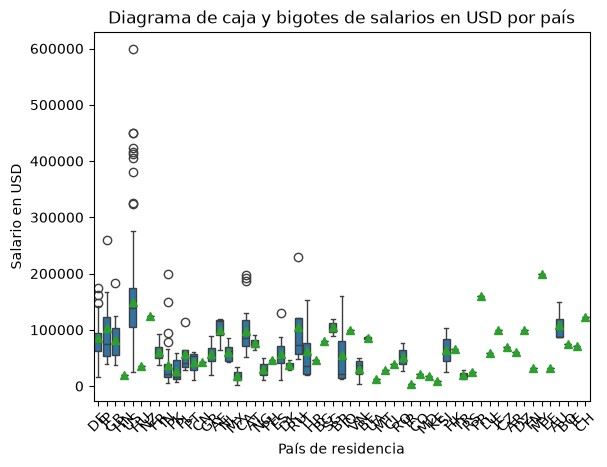

In [46]:
# Diagrama de caja y bigotes de la variable 'salary_in_usd' por país
sns.boxplot(x='employee_residence', y='salary_in_usd', showmeans=True, data=df)
plt.xlabel('País de residencia')
plt.ylabel('Salario en USD')
plt.title('Diagrama de caja y bigotes de salarios en USD por país')
plt.xticks(rotation=45)
plt.show()

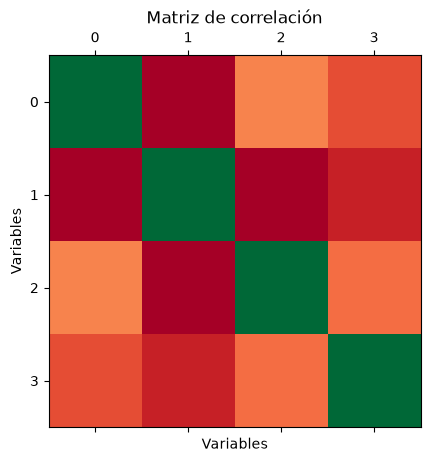

In [47]:
# Gráfico de correlación

# Creamos un mapa de calor de la matriz de correlación
plt.matshow(corr_matrix, cmap='RdYlGn')
plt.title('Matriz de correlación')
plt.xlabel('Variables')
plt.ylabel('Variables')
plt.show()

Interpretación de la matriz de correlación

La matriz de correlación muestra la relación lineal entre dos variables. Los valores de correlación se encuentran entre -1 y 1. Un valor de correlación de 1 indica una relación lineal positiva perfecta, un valor de correlación de -1 indica una relación lineal negativa perfecta y un valor de correlación de 0 indica que no hay relación lineal entre las dos variables.

En este conjunto de datos, la variable salary_in_usd presenta una correlación positiva débil con work_year (0.17). Esto indica una ligera asociación lineal entre el año registrado y el salario en dólares.

Asimismo, salary_in_usd presenta una correlación positiva débil con remote_ratio (0.13), por lo que no podemos afirmar que el trabajo remoto disminuya el salario.

La variable salary presenta una correlación negativa muy débil con salary_in_usd (−0.08).

Estas correlaciones no permiten establecer relaciones de causa y efecto.

En el caso de este conjunto de datos, la variable salary_in_usd tiene una correlación positiva significativa con las variables work_year y experience_level. Esto significa que a medida que aumenta el número de años de trabajo o el nivel de experiencia, también aumenta el salario.

La variable salary_in_usd también tiene una correlación negativa significativa con la variable remote_ratio. Esto significa que a medida que aumenta la proporción de trabajo remoto, disminuye el salario.

La variable company_size no tiene una correlación significativa con ninguna de las otras variables. Esto significa que el tamaño de la empresa no tiene un impacto significativo en el salario.

Gráfico de correlación con pandas

Para crear un gráfico de correlación con pandas, podemos usar la función matshow(). Esta función crea un mapa de calor de la matriz de correlación.

En el código anterior, creamos un mapa de calor de la matriz de correlación usando la función matshow(). El mapa de calor muestra que la variable salary_in_usd tiene una correlación positiva significativa con las variables work_year y experience_level.

## CONCLUSIONES

Después de analizar los 607 registros del conjunto de datos, se logró identificar la distribución de salarios en diferentes especialidades relacionadas con la ciencia de datos.

Mediante Python y las bibliotecas Pandas, Matplotlib y Seaborn, se realizaron análisis estadísticos y visualizaciones que permitieron comparar salarios, identificar valores atípicos y estudiar las relaciones entre variables.

La matriz de correlación de Pearson mostró relaciones positivas débiles entre el salario en dólares y el año de trabajo (0.17), así como entre el salario en dólares y la proporción de trabajo remoto (0.13).

Este análisis permitió comprender mejor las características del conjunto de datos y aplicar herramientas fundamentales de análisis exploratorio. Para realizar predicciones salariales confiables sería necesario desarrollar y evaluar modelos adicionales.

#REFERENCIAS Y LINKS DE APOYO
https://www.codigopiton.com/como-hacer-un-histograma-en-python/
https://cursosinformatica.ucm.es/trial/dataviz/
https://datacarpentry.org/python-ecology-lesson-es/08-putting-it-all-together/index.html
https://es.acervolima.com/como-crear-una-matriz-de-correlacion-usando-pandas/#:~:text=El%20m%C3%A9todo%20de%20Pandas%20dataframe,valor%20na%20se%20excluye%20autom%C3%A1ticamente.
https://www.analyticslane.com/2020/12/07/pandas-obtener-el-nombre-de-las-columnas-y-filas-en-pandas/